In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv


In [2]:
import pandas as pd
df=pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
df.shape

(1460, 81)

In [4]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
missing=df.isnull().sum()
print(missing)

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


In [7]:
missing[missing>0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [8]:
none_cols = [
    'Alley',
    'MasVnrType',
    'BsmtQual',
    'BsmtCond',
    'BsmtExposure',
    'BsmtFinType1',
    'BsmtFinType2',
    'FireplaceQu',
    'GarageType',
    'GarageFinish',
    'GarageQual',
    'GarageCond',
    'PoolQC',
    'Fence',
    'MiscFeature'
]

df[none_cols] = df[none_cols].fillna('None')

In [9]:
df['LotFrontage'] = df['LotFrontage'].fillna(
    df['LotFrontage'].median()
)

df['MasVnrArea'] = df['MasVnrArea'].fillna(0)

df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)

In [10]:
df['Electrical'] = df['Electrical'].fillna(
    df['Electrical'].mode()[0]
)


In [11]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [12]:
print("Numerical columns:",df.select_dtypes(include='number').shape[1])

Numerical columns: 38


In [13]:
print("category columns:",df.select_dtypes(include='object').shape[1])

category columns: 43


In [14]:
print("Duplicated rows:",df.duplicated().sum())

Duplicated rows: 0


Text(0.5, 1.0, 'sales price distribution')

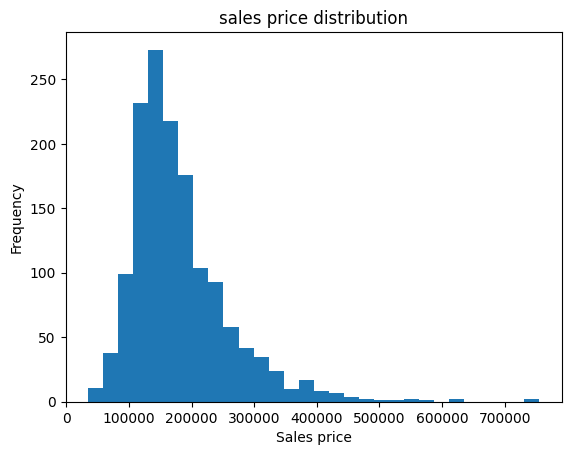

In [15]:
import matplotlib.pyplot as plt
plt.hist(df['SalePrice'],bins=30)
plt.xlabel("Sales price")
plt.ylabel("Frequency")
plt.title("sales price distribution")

In [16]:
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

In [17]:
df['TotalSF'] = (
    df['TotalBsmtSF'] +
    df['1stFlrSF'] +
    df['2ndFlrSF']
)

df['TotalBathrooms'] = (
    df['FullBath'] +
    0.5 * df['HalfBath'] +
    df['BsmtFullBath'] +
    0.5 * df['BsmtHalfBath']
)

df['TotalPorchSF'] = (
    df['OpenPorchSF'] +
    df['3SsnPorch'] +
    df['EnclosedPorch'] +
    df['ScreenPorch'] +
    df['WoodDeckSF']
)

df['HouseAge'] = df['YrSold'] - df['YearBuilt']

df['RemodAge'] = df['YrSold'] - df['YearRemodAdd']

In [18]:
df[['TotalSF', 'TotalBathrooms', 'TotalPorchSF', 'HouseAge', 'RemodAge']].head()

,TotalSF,TotalBathrooms,TotalPorchSF,HouseAge,RemodAge
0,2566,3.5,61,5,5
1,2524,2.5,298,31,31
2,2706,3.5,42,7,6
3,2473,2.0,307,91,36
4,3343,3.5,276,8,8


In [19]:
X=df.drop(columns=["SalePrice"])
y=df["SalePrice"]

In [20]:
print("X shape:",X.shape)
print("y shape:",y.shape)

X shape: (1460, 85)
y shape: (1460,)


In [21]:
print("categorical values",df.select_dtypes(include='object').shape[1])

categorical values 43


In [22]:
print("numerical values",df.select_dtypes(include='number').shape[1])

numerical values 43


In [23]:
print("Total columns:", X.shape[1])
print("Categorical:", X.select_dtypes(include='object').shape[1])
print("Numerical:", X.select_dtypes(include='number').shape[1])

Total columns: 85
Categorical: 43
Numerical: 42


In [24]:
X_encoded=pd.get_dummies(X,drop_first=True,dtype=int)
print("before_encoding:",X.shape)
print("after_encoding:",X_encoded.shape)

before_encoding: (1460, 85)
after_encoding: (1460, 265)


In [26]:
from sklearn.model_selection import train_test_split

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X_encoded,y,test_size=0.2,random_state=42)

In [35]:
from sklearn.linear_model import LinearRegression
lr_model=LinearRegression()
lr_model.fit(X_train,y_train)
lrPred=lr_model.predict(X_test)

In [36]:
from sklearn.metrics import mean_absolute_error

In [38]:
lr_mae=mean_absolute_error(y_test,lrPred)
print(lr_mae)

23922.62678223198


In [41]:
from sklearn.metrics import root_mean_squared_error
lr_rmse=root_mean_squared_error(y_test,lrPred)
print(lr_rmse)

83010.70186874804


In [43]:
from sklearn.metrics import r2_score
lr_rsquare=r2_score(y_test,lrPred)
print(lr_rsquare)

0.10163186823977755


In [49]:
from sklearn.tree import DecisionTreeRegressor
dt=DecisionTreeRegressor()
dt.fit(X_train,y_train)
dtpred=dt.predict(X_test)


In [52]:
dt_mae=mean_absolute_error(y_test,dtpred)
print(dt_mae)
from sklearn.metrics import root_mean_squared_error
dt_rmse=root_mean_squared_error(y_test,dtpred)
print(dt_rmse)
from sklearn.metrics import r2_score
dt_rsquare=r2_score(y_test,dtpred)
print(dt_rsquare)

25757.18493150685
40485.33128623458
0.7863112982313116


In [54]:
dt_train_pred=dt.predict(X_train)
print("training_r2score:",r2_score(y_train,dt_train_pred))
print("test_r2score:",r2_score(y_test,dtpred))

training_r2score: 1.0
test_r2score: 0.7863112982313116


In [58]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
param_grid={
    'max_depth':[3,5,7,10,15,20,None],
    'min_samples_leaf':[1,2,5,10],
    'min_samples_split':[2,5,10,20],
    'max_leaf_nodes':[None,50,100,200,]
}
grid_search=GridSearchCV(dt,param_grid,cv=5,scoring='r2',n_jobs=-1)
grid_search.fit(X_train,y_train)
print("best parameter:",grid_search.best_params_)
print("best cv2:",grid_search.best_score_)

best parameter: {'max_depth': 7, 'max_leaf_nodes': 50, 'min_samples_leaf': 10, 'min_samples_split': 5}
best cv2: 0.7646599944099396


In [59]:
best_dt = DecisionTreeRegressor(
    max_depth=7,
    max_leaf_nodes=50,
    min_samples_leaf=10,
    min_samples_split=5,
    random_state=42
)

best_dt.fit(X_train, y_train)

pred_best = best_dt.predict(X_test)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, pred_best))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_best)))
print("R²:", r2_score(y_test, pred_best))

MAE: 22691.35421589575
RMSE: 36645.43699734294
R²: 0.8249242579190518


In [60]:
pred_train_best = best_dt.predict(X_train)

print("Tuned Train R²:", r2_score(y_train, pred_train_best))
print("Tuned Test R²:", r2_score(y_test, pred_best))

Tuned Train R²: 0.8825726341092475
Tuned Test R²: 0.8249242579190518
